# Capstone – Lightning Talk 2
## Powerlifting Lift Judge: computer vision that judges squat and deadlift technique from video

**Abdulaziz Abdulhadi** · GA Data Science Bootcamp (DSB-PT-4, Bahrain 2026)

Contents: updated problem statement · data · EDA (target, feature types, categories, nulls, correlations,
outliers) · feature engineering · evaluation · limitations · final output and data collection.

## 1. Updated problem statement

In powerlifting a lift only counts if three referees agree it met the IPF rules: in the squat, the hip
crease must go below the top of the knee; in the deadlift, the lifter must finish with knees locked and
shoulders back, without the bar going down or resting on the thighs. These calls are made by eye in a
fraction of a second, close calls are disputed, and lifters training alone have no referee at all. Many
first-time competitors find out at the meet that their squat is "high".

**Can a phone video and pretrained pose estimation judge each rep against the IPF rules, explain the
call, and refuse to call it when the video can't support a decision?**

| | |
|---|---|
| **Who** | lifters (check training sets), coaches (remote technique review), federations (second opinion, referee training) |
| **What it predicts** | per rep: good lift / no lift (+ which IPF fault, with the referee card colour) |
| **How** | YOLO26-pose keypoints → time-series signals → rep segmentation → IPF rule engine + a Keras sequence model |
| **What changed since Lightning Talk 1** | squat **and** deadlift; camera-angle detection (front views are not judged for depth); a working CLI, web demo, Flutter app and API |

## 2. The data

**Source.** The pipeline turns each video into numbers: the pose model (YOLO26-pose, pretrained on COCO,
17 body keypoints) gives joint positions per frame; the pipeline turns them into signals (depth, joint angles,
velocities) and per-rep measurements.

**Development dataset.** Real labelled lifting videos are being collected now (see section 8). To build
and test the pipeline before that, it is run on **simulated lifters**: 60 people with their own tempo,
keypoint noise, frame rate (30/60 fps), filmed side, camera position (80% side, 12% angled, 8% front) and
detection drop-outs. The **labels come from what the simulator did** (e.g. depth 2° above parallel, a
hitch), not from the rule engine, so testing the rules against them is fair.

Two tables:
- **reps**: 2,400 rows × 24 columns, one row per rep
- **frames**: ~286,000 rows × 15 columns, one row per video frame (the sequence the neural network reads)

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(exist_ok=True)
RED, WHITE_LIGHT, GREY = "#D62828", "#3a7d44", "#7a7d85"

from liftjudge.devdata import build_dev_dataset
cache = ROOT / "data" / "processed"
if (cache / "reps.csv").exists() and (cache / "frames.csv").exists():
    reps, frames = pd.read_csv(cache / "reps.csv"), pd.read_csv(cache / "frames.csv")
else:
    reps, frames = build_dev_dataset(n_squat=1500, n_deadlift=900, n_lifters=60, seed=0)   # ~1 min
    cache.mkdir(parents=True, exist_ok=True)
    reps.to_csv(cache / "reps.csv", index=False); frames.to_csv(cache / "frames.csv", index=False)
print("reps:", reps.shape, "  frames:", frames.shape)
reps.head()

reps: (2400, 24)   frames: (285833, 15)


,rep_id,lifter_id,lift,camera_view,filmed_side,fps,duration_s,depth_margin,lockout_knee_angle,lockout_hip_angle,bounce,downward_drop,hitch_rebend_deg,feet_shift,down_phase_s,up_phase_s,sticking_speed,horizontal_drift,keypoint_conf,missing_frames_pct,rule_status,fault_type,faults,good_lift
0,R00000,L020,squat,side,right,60,1.650,-0.117052,179.983845,NaN,0.285285,0.000000,NaN,0.023570,0.850000,0.800000,1.102602,0.516959,0.900000,0.00,fail,multiple,depth+bounce,0
1,R00001,L053,squat,side,right,60,1.100,0.187885,179.664344,NaN,0.000000,0.000000,NaN,0.022590,0.466667,0.633333,1.708899,0.576147,0.900000,0.00,pass,none,NaN,1
2,R00002,L043,squat,side,left,60,1.717,-0.199453,179.915562,NaN,0.270513,0.000000,NaN,0.010120,0.866667,0.850000,1.049156,0.515065,0.830769,6.02,fail,multiple,depth+bounce,0
3,R00003,L025,deadlift,side,right,30,3.833,NaN,179.950742,179.994288,NaN,0.064084,18.120738,0.046160,NaN,1.566667,-0.476005,0.562855,0.900000,0.00,fail,hitching,hitching,0
4,R00004,L014,deadlift,side,right,30,2.300,NaN,179.989100,179.987402,NaN,0.000000,0.000000,0.033105,NaN,0.600000,0.373907,0.727117,0.771429,14.00,pass,none,NaN,1


### Data dictionary: `reps` (one row per rep)

| Column | Type | Description |
|---|---|---|
| rep_id, lifter_id | id | rep and (simulated) lifter |
| lift | categorical | squat / deadlift |
| camera_view | categorical | detected from keypoints: side / angled / front |
| filmed_side | categorical | which side of the body faces the camera |
| fps | categorical | video frame rate (30 / 60) |
| duration_s | numerical | rep length |
| depth_margin | numerical | squat only: hip below knee at the bottom minus the crease offset (thigh lengths; > 0 = deep enough) |
| lockout_knee_angle | numerical | max knee angle at the finish / lockout (°) |
| lockout_hip_angle | numerical | deadlift only: hip angle at lockout (°), 180 = standing erect |
| bounce | numerical | squat only: biggest rise-then-drop of the hips in the hole (thighs) |
| downward_drop | numerical | biggest downward movement on the way up (thighs) |
| hitch_rebend_deg | numerical | deadlift only: knee re-bend during the pull (°) |
| feet_shift | numerical | biggest ankle movement during the rep (thighs) |
| down_phase_s / up_phase_s | numerical | descent time (squat) / ascent or pull time |
| sticking_speed | numerical | slowest speed in the middle of the ascent/pull (thighs/s) |
| horizontal_drift | numerical | horizontal sway of the bar position (thighs) |
| keypoint_conf | numerical | mean pose-model confidence on hip, knee, ankle |
| missing_frames_pct | numerical | % of frames where the detector lost the legs |
| rule_status | categorical | the rule engine's call: pass / fail / borderline (comparison only, **not** a feature) |
| fault_type, faults | categorical | the true fault(s) |
| **good_lift** | **binary target** | 1 = good lift (three white lights), 0 = no lift |

In [2]:
frames.head()

,rep_id,lift,frame,time_s,depth,hip_height,bar_height,knee_angle,hip_angle,elbow_angle,hip_vel,ankle_dx,leg_conf,raw_hip_y,good_lift
0,R00000,squat,0,0.000,-1.0005,2.0042,3.2455,178.14,178.67,2.30,0.1848,0.0000,0.9,501.158649,0
1,R00000,squat,1,0.017,-1.0016,2.0016,3.2399,177.67,177.68,1.76,0.0060,0.0069,0.9,498.606019,0
2,R00000,squat,2,0.033,-1.0048,2.0054,3.2435,177.11,177.11,1.93,0.0532,0.0084,0.9,499.209398,0
3,R00000,squat,3,0.050,-1.0007,2.0040,3.2473,176.05,176.02,1.86,0.0547,0.0070,0.9,504.040774,0
4,R00000,squat,4,0.067,-1.0036,2.0019,3.2425,174.83,174.60,2.37,-0.0739,0.0049,0.9,496.144658,0


## 3. EDA

### Q1. What is the target column and what does it represent?
**`good_lift`**: 1 if the rep meets every judged IPF rule for its lift (a referee would give a white
light), 0 if it has at least one fault. A secondary, multi-class target `fault_type` says *which* rule failed
(depth, lockout, bounce, downward movement, hitching, feet, or multiple), which maps to the referee card colours.

### Q2. Categorical or continuous? Is it balanced?

good_lift
0    0.558
1    0.442
Name: proportion, dtype: float64


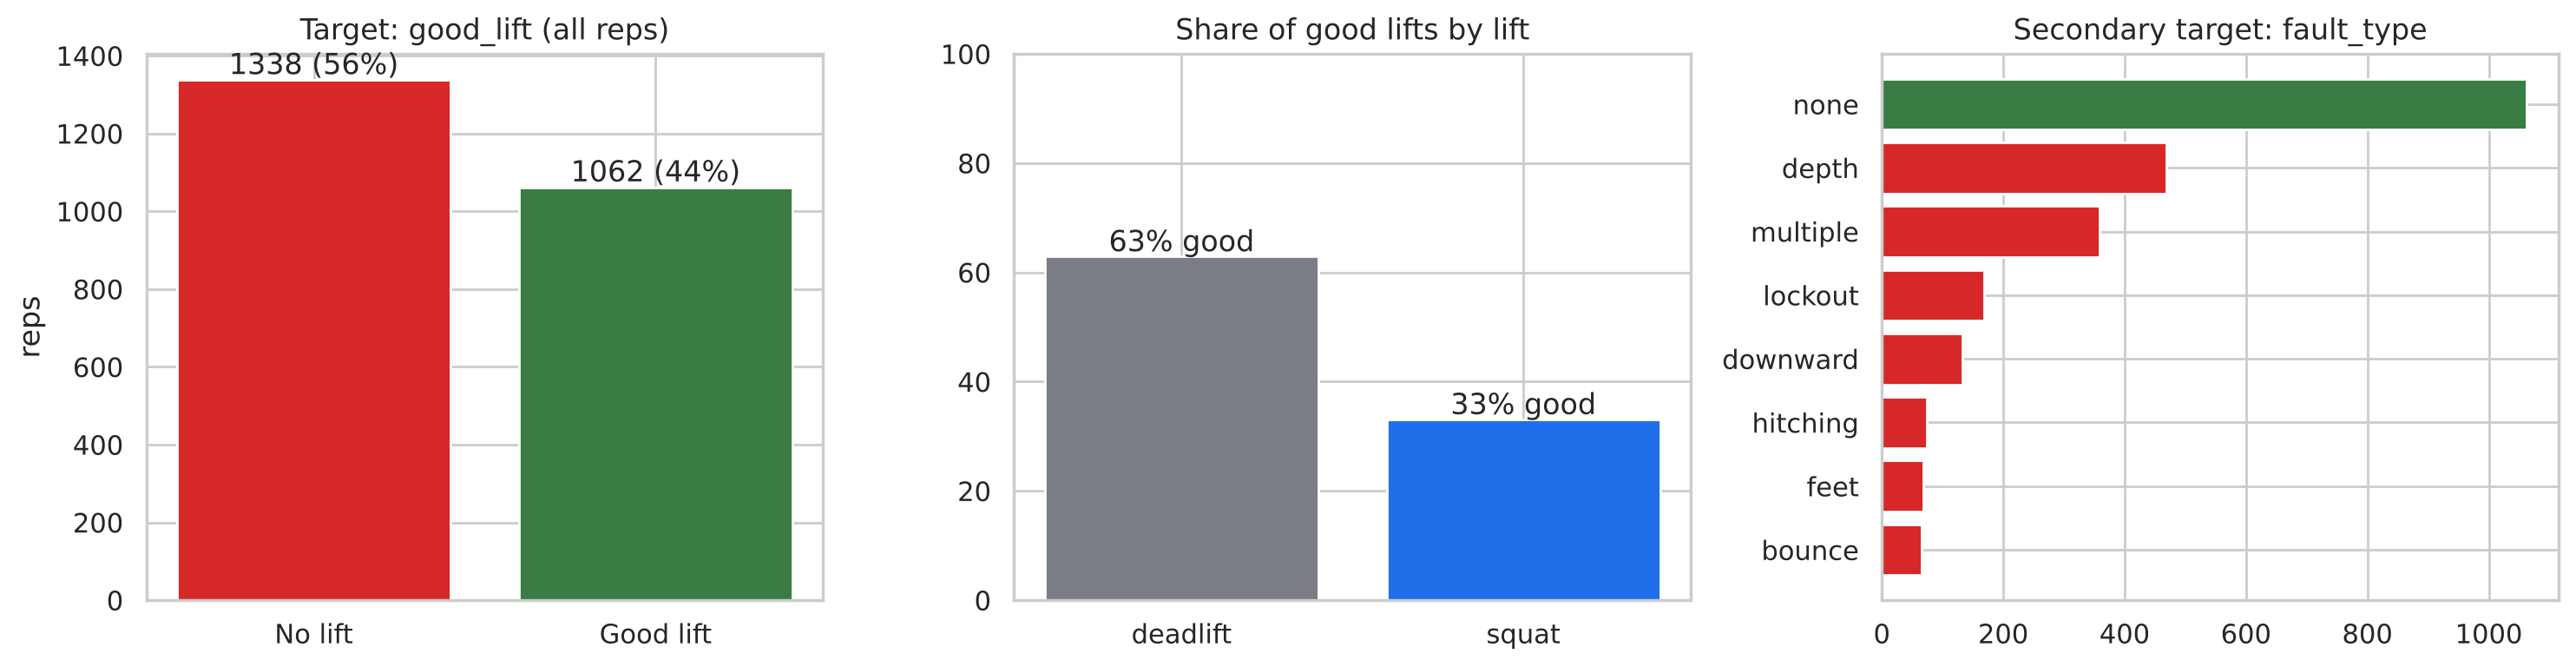

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
counts = reps.good_lift.map({1: "Good lift", 0: "No lift"}).value_counts()
ax[0].bar(counts.index, counts.values, color=[RED if i == "No lift" else WHITE_LIGHT for i in counts.index])
for i, v in enumerate(counts.values): ax[0].text(i, v + 15, f"{v} ({v / len(reps):.0%})", ha="center")
ax[0].set_title("Target: good_lift (all reps)"); ax[0].set_ylabel("reps")
by_lift = reps.groupby("lift").good_lift.mean().mul(100)
ax[1].bar(by_lift.index, by_lift.values, color=[GREY, "#1F6FEB"])
for i, v in enumerate(by_lift.values): ax[1].text(i, v + 1, f"{v:.0f}% good", ha="center")
ax[1].set_ylim(0, 100); ax[1].set_title("Share of good lifts by lift")
ft = reps.fault_type.value_counts()
ax[2].barh(ft.index[::-1], ft.values[::-1], color=[WHITE_LIGHT if i == "none" else RED for i in ft.index[::-1]])
ax[2].set_title("Secondary target: fault_type")
plt.tight_layout(); plt.savefig(FIG / "lt2_target.png", dpi=160, bbox_inches="tight")
print(reps.good_lift.value_counts(normalize=True).round(3))

**Answer.** `good_lift` is **categorical (binary)**. Overall it is **moderately imbalanced: 44% good / 56% no lift**,
and it differs a lot by lift (squat 33% good, deadlift 63% good) because depth is the most common squat fault.
`fault_type` is multi-class and strongly imbalanced (depth dominates; feet and bounce are rare).

In real training videos most reps are good, so the real class balance will flip; that's why the evaluation
uses recall/precision per class rather than accuracy, and splits by lifter.

### Q3. What types of features are there, and how many of each?

In [4]:
target_cols = ["good_lift", "fault_type", "faults"]
id_cols = ["rep_id", "lifter_id"]
not_features = id_cols + target_cols + ["rule_status"]
cat_features = ["lift", "camera_view", "filmed_side", "fps"]
num_features = [c for c in reps.columns if c not in not_features + cat_features]
print(f"categorical features ({len(cat_features)}):", cat_features)
print(f"numerical features ({len(num_features)}):", num_features)
sig_cols = [c for c in frames.select_dtypes("number").columns if c not in ("frame", "time_s", "good_lift")]
print(f"\nframes table: {frames.shape[1]} columns; {len(sig_cols)} numerical signals per frame:", sig_cols)

categorical features (4): ['lift', 'camera_view', 'filmed_side', 'fps']
numerical features (14): ['duration_s', 'depth_margin', 'lockout_knee_angle', 'lockout_hip_angle', 'bounce', 'downward_drop', 'hitch_rebend_deg', 'feet_shift', 'down_phase_s', 'up_phase_s', 'sticking_speed', 'horizontal_drift', 'keypoint_conf', 'missing_frames_pct']

frames table: 15 columns; 10 numerical signals per frame: ['depth', 'hip_height', 'bar_height', 'knee_angle', 'hip_angle', 'elbow_angle', 'hip_vel', 'ankle_dx', 'leg_conf', 'raw_hip_y']


**Answer.** Rep table: **4 categorical** features (lift, camera_view, filmed_side, fps) and **14 numerical**
features (measurements in thigh lengths, degrees and seconds), plus ids, the rule engine's call and the targets.
The frames table holds **10 numerical signals per frame** over time (the input of the sequence model).

### Q4. Unique values of each categorical feature, and their percentage

lift: squat 62.5%, deadlift 37.5%
camera_view: side 87.5%, angled 8.5%, front 4.0%
filmed_side: right 64.9%, left 35.1%
fps: 30 51.7%, 60 48.2%
fault_type: none 44.2%, depth 19.5%, multiple 15.0%, lockout 7.0%, downward 5.5%, hitching 3.1%, feet 2.8%, bounce 2.8%
rule_status: fail 51.6%, pass 39.2%, borderline 9.2%


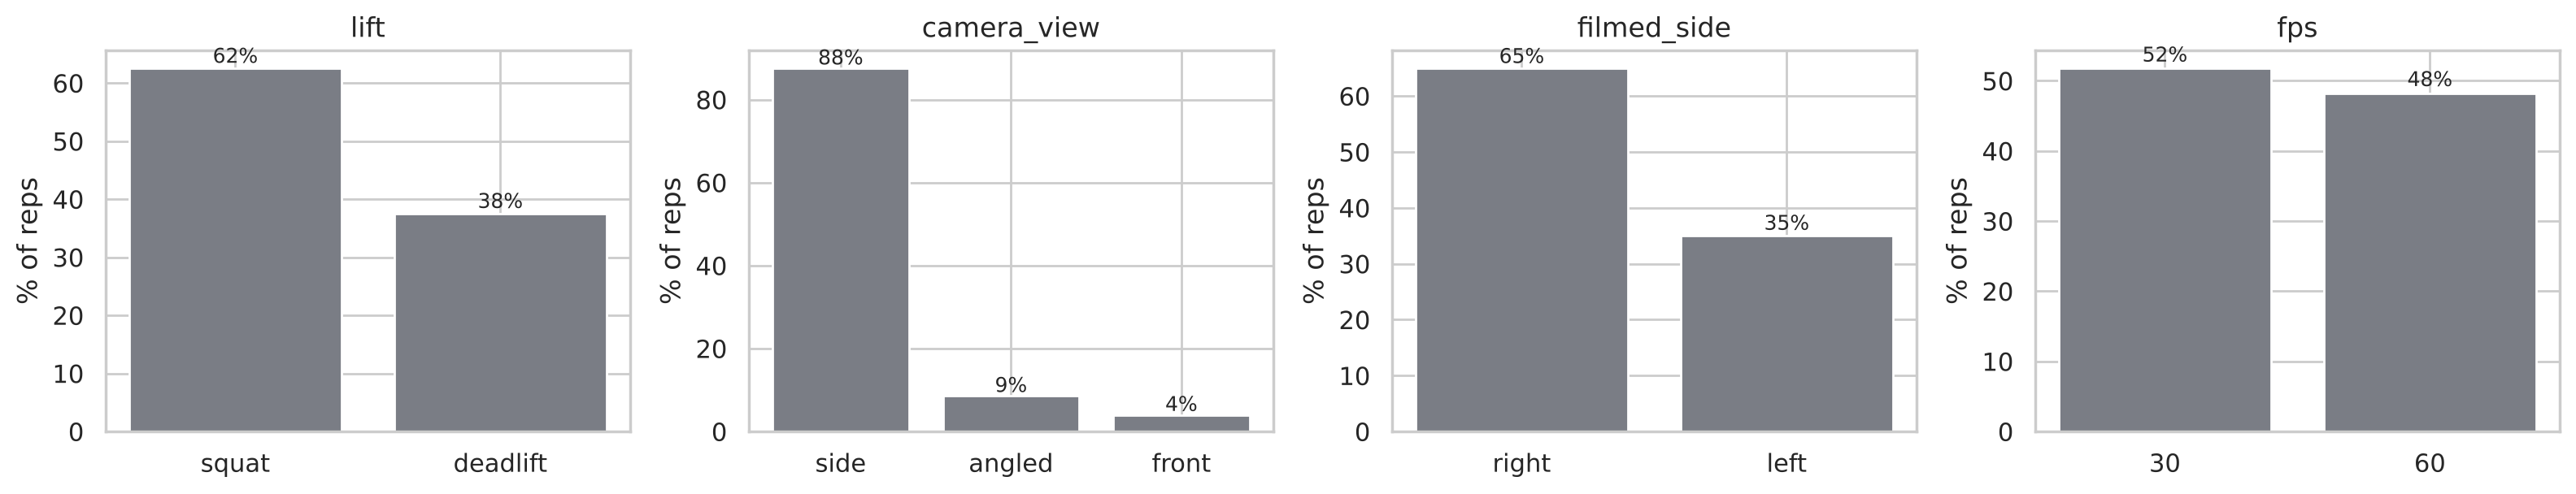

In [5]:
for c in cat_features + ["fault_type", "rule_status"]:
    vc = reps[c].value_counts()
    print(f"{c}: " + ", ".join(f"{k} {v / len(reps):.1%}" for k, v in vc.items()))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, c in zip(ax, cat_features):
    vc = reps[c].astype(str).value_counts(normalize=True).mul(100)
    a.bar(vc.index, vc.values, color=GREY); a.set_title(c); a.set_ylabel("% of reps")
    for i, v in enumerate(vc.values): a.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "lt2_categories.png", dpi=160, bbox_inches="tight")

**Answer.** lift: squat 62.5%, deadlift 37.5% · camera_view: side 87.5%, angled 8.5%, front 4.0% · filmed_side:
right 65%, left 35% · fps: 30 fps 52%, 60 fps 48% · rule_status: fail 52%, pass 39%, borderline 9%. The camera view matters most: front-view reps
can't be judged for depth, and the rule engine returns *borderline* for them instead of guessing.

### Q5. How many null values does each feature have?

In [6]:
nulls = reps[num_features].isna().sum()
nulls = pd.DataFrame({"nulls": nulls, "%": (nulls / len(reps) * 100).round(1)})
print(nulls[nulls.nulls > 0])
print("\nnulls by lift (structural):")
print(reps.groupby("lift")[["depth_margin", "bounce", "down_phase_s", "lockout_hip_angle", "hitch_rebend_deg"]].apply(lambda d: d.isna().mean().round(2)))
print(f"\nframes.raw_hip_y nulls: {frames.raw_hip_y.isna().sum():,} ({frames.raw_hip_y.isna().mean():.1%}) = frames where the detector lost the hip")

                   nulls     %
depth_margin         900  37.5
lockout_hip_angle   1500  62.5
bounce               900  37.5
hitch_rebend_deg    1500  62.5
down_phase_s         900  37.5

nulls by lift (structural):
          depth_margin  bounce  down_phase_s  lockout_hip_angle  hitch_rebend_deg
lift                                                                             
deadlift           1.0     1.0           1.0                0.0               0.0
squat              0.0     0.0           0.0                1.0               1.0

frames.raw_hip_y nulls: 10,389 (3.6%) = frames where the detector lost the hip


**Answer.** There are no random nulls in the rep table: every null is **structural**. Squat-only measurements
(`depth_margin`, `bounce`, `down_phase_s`: 900 nulls each = the deadlifts) and deadlift-only measurements
(`lockout_hip_angle`, `hitch_rebend_deg`: 1,500 nulls each = the squats) don't exist for the other lift.
Plan: model each lift separately (no imputation needed), or fill with 0 plus a lift indicator for a joint model.

The real missing data is in the **frames**: `raw_hip_y` is null wherever the pose model lost the lifter (10,389
frames = 3.6%, up to 12% for some lifters). The pipeline fills these gaps by interpolation before smoothing, and
`missing_frames_pct` keeps how much was filled as a reliability feature.

### Q6. Which features are most correlated with the target, and with each other?

squat top |corr|: {'depth_margin': 0.61, 'sticking_speed': 0.36, 'downward_drop': 0.26, 'bounce': 0.25}
deadlift top |corr|: {'sticking_speed': 0.62, 'hitch_rebend_deg': 0.61, 'downward_drop': 0.6, 'lockout_hip_angle': 0.53}



strongest feature pairs (squat):
up_phase_s      duration_s            0.94
keypoint_conf   missing_frames_pct    0.93
down_phase_s    duration_s            0.91
sticking_speed  downward_drop         0.89
feet_shift      horizontal_drift      0.77
dtype: float64


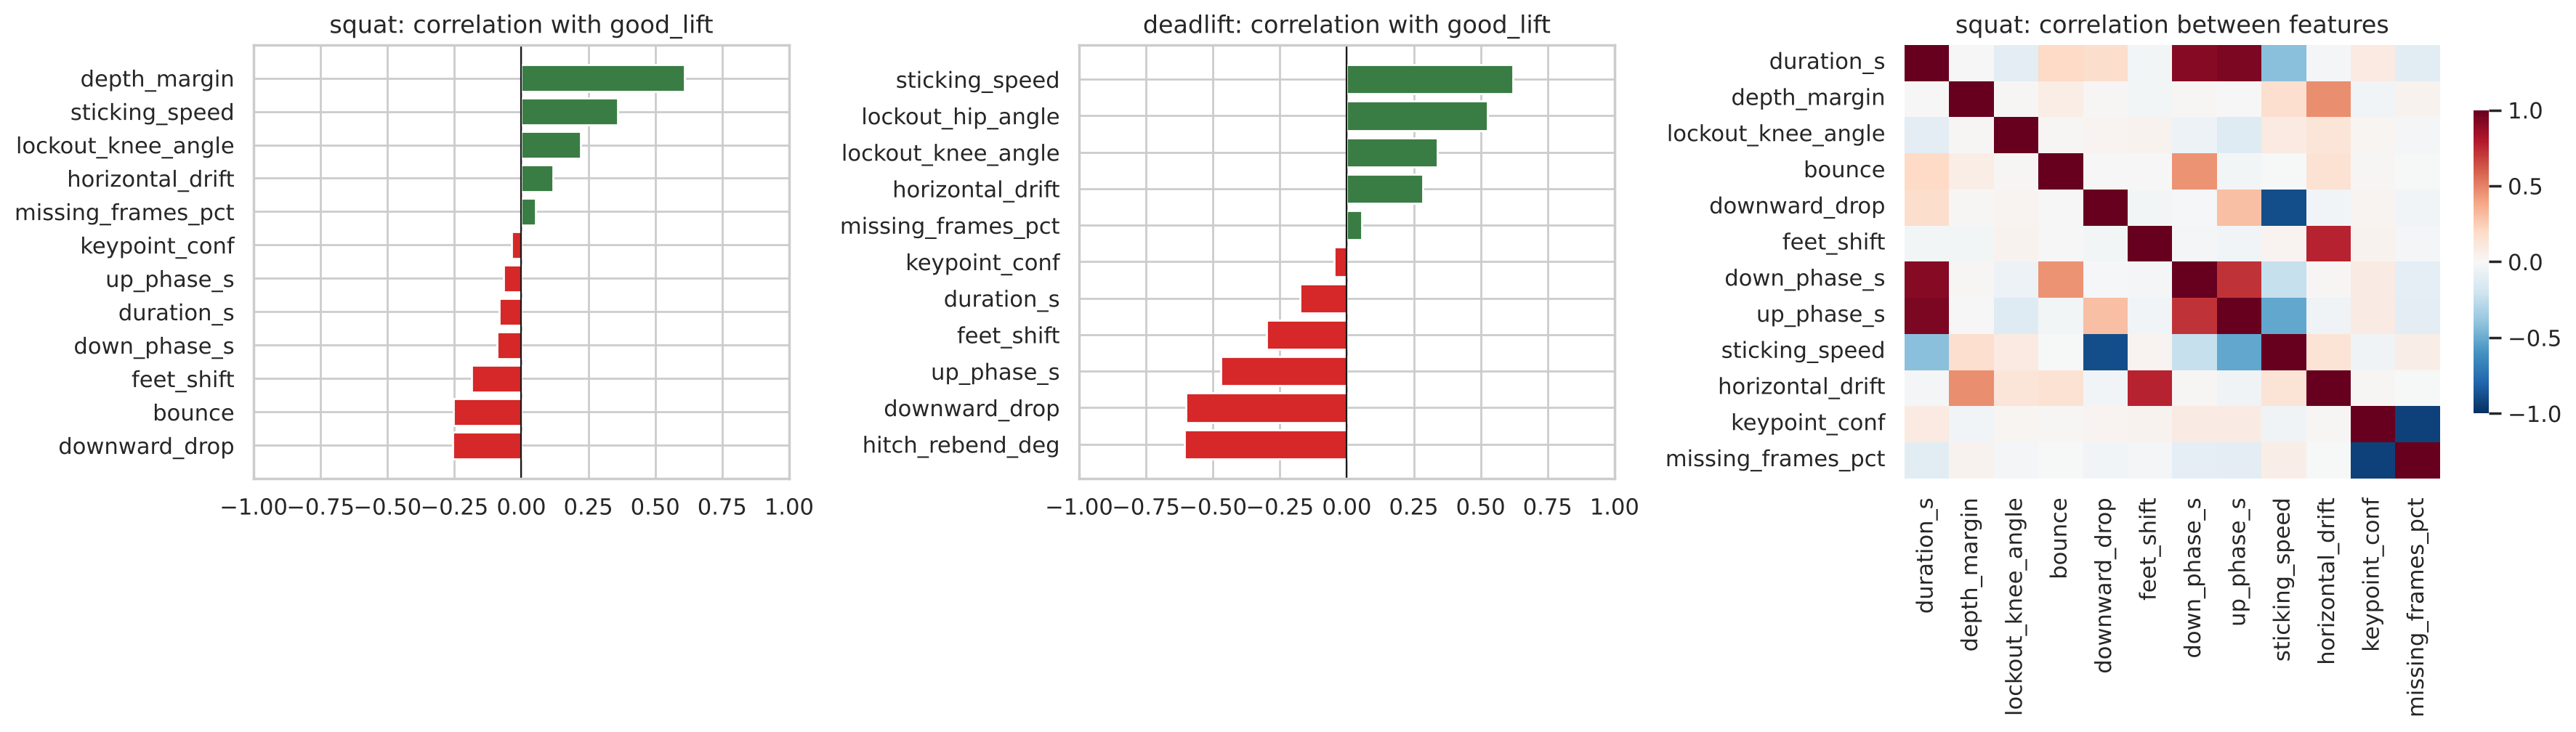

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.25]})
for a, lift in zip(ax[:2], ["squat", "deadlift"]):
    d = reps[reps.lift == lift]
    cols = [c for c in num_features if d[c].notna().all()]
    corr = d[cols + ["good_lift"]].corr()["good_lift"].drop("good_lift").sort_values()
    a.barh(corr.index, corr.values, color=[RED if v < 0 else WHITE_LIGHT for v in corr.values])
    a.axvline(0, color="k", lw=0.8); a.set_xlim(-1, 1); a.set_title(f"{lift}: correlation with good_lift")
    print(f"{lift} top |corr|:", corr.abs().sort_values(ascending=False).head(4).round(2).to_dict())
d = reps[reps.lift == "squat"]
cols = [c for c in num_features if d[c].notna().all()]
sns.heatmap(d[cols].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[2], cbar_kws={"shrink": 0.7})
ax[2].set_title("squat: correlation between features")
plt.tight_layout(); plt.savefig(FIG / "lt2_correlation.png", dpi=160, bbox_inches="tight")
c = d[cols].corr().abs().where(~np.eye(len(cols), dtype=bool)).stack().sort_values(ascending=False)
print("\nstrongest feature pairs (squat):"); print(c[::2].head(5).round(2))

**Answer.** For the **squat**, `depth_margin` is by far the strongest predictor (r = 0.61: it *is* the depth
rule), then `sticking_speed` (0.36), `downward_drop` (−0.26) and `bounce` (−0.25). For the **deadlift**,
`sticking_speed` (0.62), `hitch_rebend_deg` (−0.61), `downward_drop` (−0.60) and `lockout_hip_angle` (0.53) lead:
a bar that slows to zero or drops, knees that re-bend, and a soft lockout all mean no lift. Between features:
duration ↔ phase times (0.91–0.94, one tempo per lifter), `keypoint_conf` ↔ `missing_frames_pct` (0.93, both
measure video quality) and `sticking_speed` ↔ `downward_drop` (0.89: a negative speed *is* a downward movement),
so a linear model should keep only one of each pair. Correlation is linear only: depth has a threshold effect, which is why the rules
and tree models handle it better than a straight line.

### Q7. Are there outliers?

,feature,outliers (IQR),%,% of outliers that are no-lifts
0,depth_margin,0,0.0,NaN
1,downward_drop,459,19.1,92.0
2,bounce,260,17.3,88.0
3,feet_shift,158,6.6,97.0
4,sticking_speed,235,9.8,98.0
5,lockout_knee_angle,406,16.9,80.0


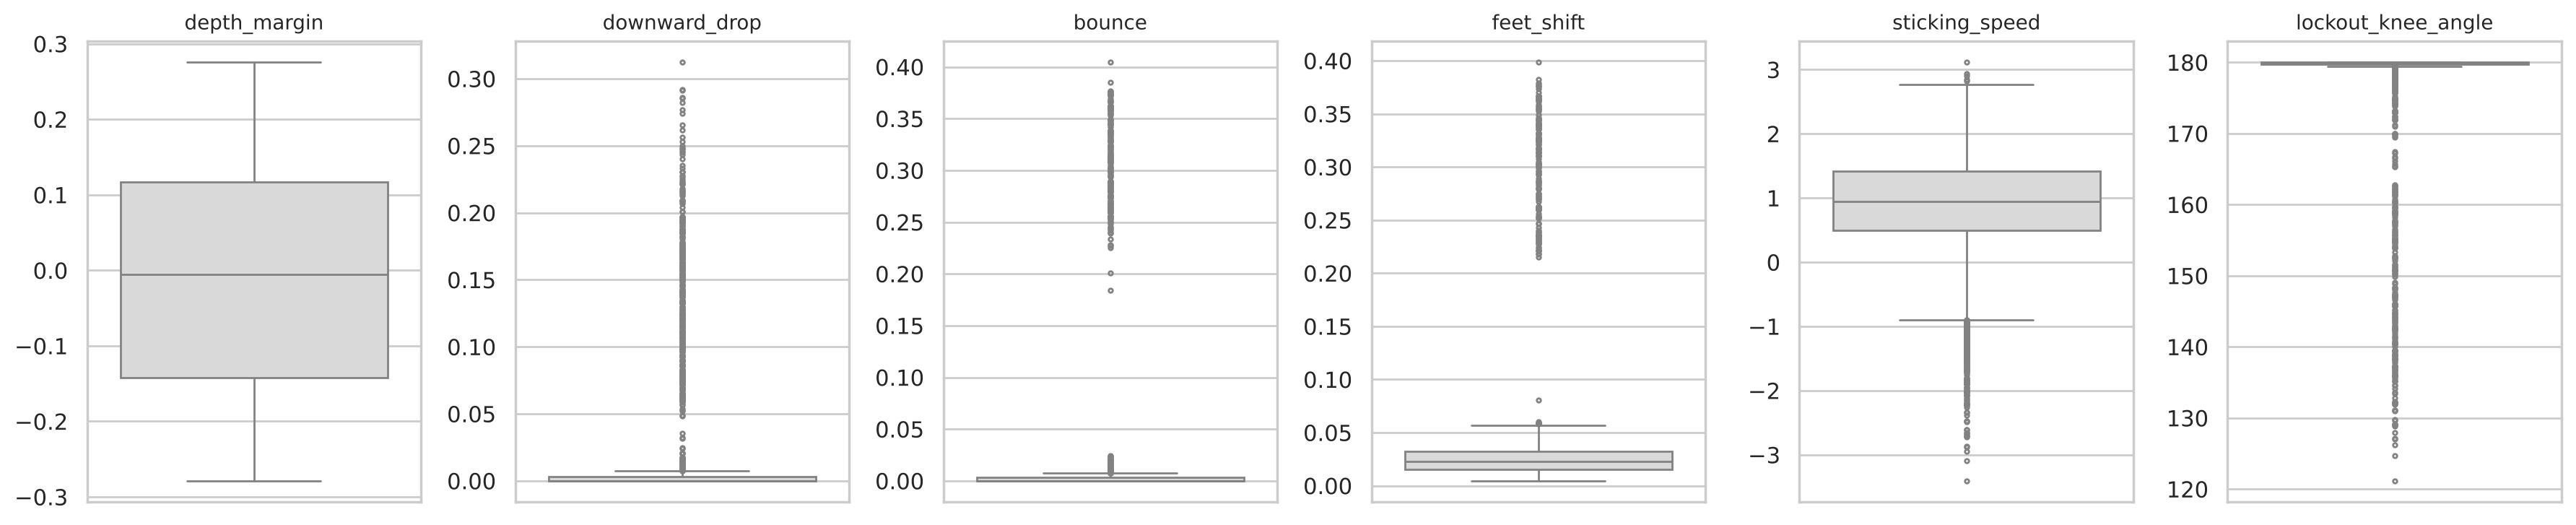

In [8]:
show = ["depth_margin", "downward_drop", "bounce", "feet_shift", "sticking_speed", "lockout_knee_angle"]
fig, ax = plt.subplots(1, len(show), figsize=(18, 3.8))
rows = []
for a, c in zip(ax, show):
    s = reps[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr))
    rows.append({"feature": c, "outliers (IQR)": int(out.sum()), "%": round(out.mean() * 100, 1),
                 "% of outliers that are no-lifts": round((1 - reps.loc[s[out].index, "good_lift"].mean()) * 100) if out.any() else None})
    sns.boxplot(y=s, ax=a, color="#d9d9d9", fliersize=2); a.set_title(c, fontsize=10); a.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "lt2_outliers.png", dpi=160, bbox_inches="tight")
pd.DataFrame(rows)

**Answer.** Yes, and **most outliers are the signal, not noise**: 88–98% of the IQR outliers in `downward_drop`,
`bounce`, `feet_shift` and `sticking_speed` are no-lifts (e.g. 459 `downward_drop` outliers, 92% no-lifts), so they
must **not** be removed. Real noise outliers come from tracking errors (e.g. low `keypoint_conf`, high
`missing_frames_pct`, front views); those are handled by flagging the rep as unreliable (borderline) rather than
deleting it. `sticking_speed` has negative values: the bar moving down during the ascent, another fault signal.

## 4. Feature engineering: what new features could improve the model?

| New feature | From | Why it helps |
|---|---|---|
| **Per-lifter normalisation** (z-score of depth/angles vs the lifter's own reps) | lifter_id + measurements | bodies differ (long femurs, mobility); "deep for this lifter" generalises better |
| **Tempo ratio** = up_phase / down_phase, time under tension | phase times | grinding reps and pauses are where faults hide |
| **Velocity profile**: min/mean speed, number of speed reversals | frame signals | a reversal = downward movement or a bounce; more robust than one threshold |
| **Bar-path deviation** from a vertical line | wrist/shoulder x over time | bar drifting forward predicts failed or hitched deadlifts |
| **Limb ratio** thigh/shin length | keypoints | changes how depth looks at the same hip angle |
| **Reliability score** = keypoint_conf × (1 − missing %) × side-view | video quality columns | lets the model abstain on bad video instead of guessing |
| **Left–right asymmetry** | both sides (angled/front views) | knee cave, uneven lockout |
| **Learned sequence features** (Conv1D + GRU) | the whole frames sequence (96 × 10) | the network learns the shapes (dip, bounce, hitch) instead of hand-made thresholds |

Quick check: does the tempo ratio separate squats with a downward movement? (median 1.56 without vs 2.10 with)

              mean   50%
has_downward            
False         1.53  1.56
True          2.02  2.10


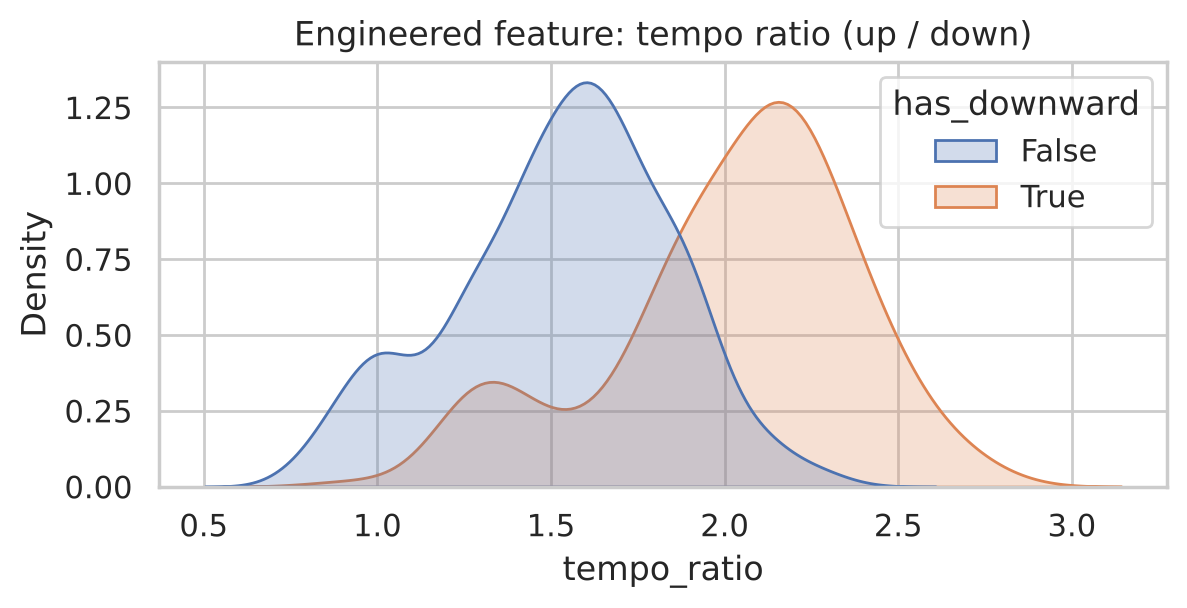

In [9]:
sq = reps[reps.lift == "squat"].copy()
sq["tempo_ratio"] = sq.up_phase_s / sq.down_phase_s
sq["has_downward"] = sq.faults.str.contains("downward")
print(sq.groupby("has_downward").tempo_ratio.describe()[["mean", "50%"]].round(2))
fig, ax = plt.subplots(figsize=(6, 3.2))
sns.kdeplot(data=sq, x="tempo_ratio", hue="has_downward", common_norm=False, fill=True, ax=ax, clip=(0, 6))
ax.set_title("Engineered feature: tempo ratio (up / down)")
plt.tight_layout(); plt.savefig(FIG / "lt2_feature_eng.png", dpi=160, bbox_inches="tight")

## 5. How will the model be evaluated? Which metrics matter most?

**Business context.** The costly mistake is approving a bad lift: a lifter trains a high squat for months and
gets red lights at the meet. Calling a good lift bad is annoying but the lifter can review the video.

| Metric | Why |
|---|---|
| **Recall on no-lift** (main) | share of bad lifts the judge catches |
| **Precision on no-lift** | share of red lights that were right (trust) |
| **F1 per fault** | depth, lockout, bounce, downward, hitching, feet each need to work |
| **Borderline (abstain) rate** | how often it refuses to call; low is good, but not at the cost of wrong calls |
| **Agreement with human referees** (Cohen's κ) | on real videos, compared with 2 judges; their own agreement is the ceiling |
| **PR-AUC** | for the neural network's probabilities, threshold-free |

Validation: **split by lifter** (GroupKFold), so the model is always tested on people it has never seen.

Baseline already measured: the **rule engine** on the development dataset:

recall on no-lift (decided reps): 0.996   precision on no-lift: 1.000


borderline / abstain rate: 9.2%
camera_view
angled    0.22
front     0.65
side      0.05
Name: borderline rate by view, dtype: float64


good_lift,true good,true no lift
rule_status,,
borderline,125,95
fail,0,1238
pass,937,5


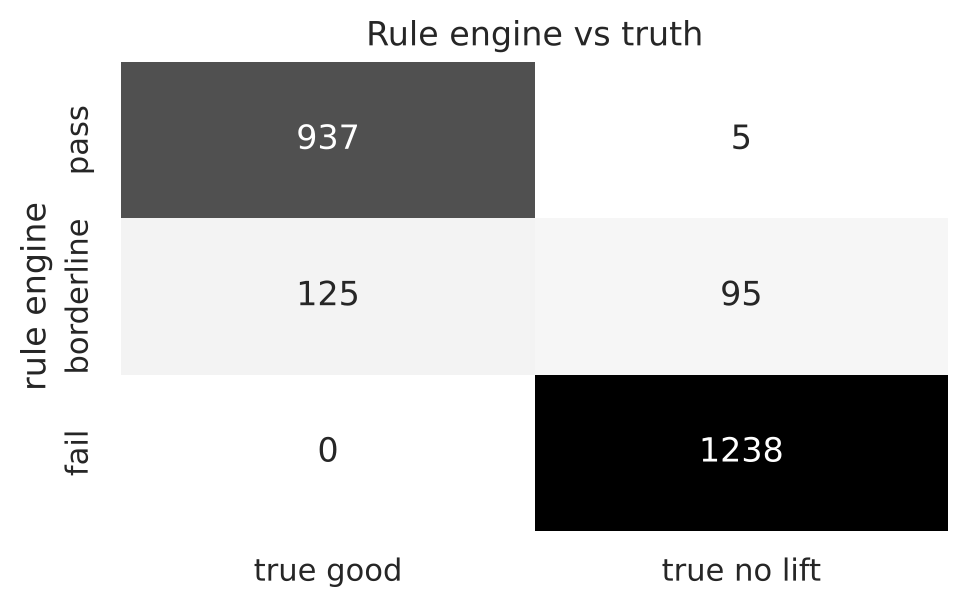

In [10]:
decided = reps[reps.rule_status != "borderline"]
tp = ((decided.rule_status == "fail") & (decided.good_lift == 0)).sum()
fn = ((decided.rule_status == "pass") & (decided.good_lift == 0)).sum()
fp = ((decided.rule_status == "fail") & (decided.good_lift == 1)).sum()
print(f"recall on no-lift (decided reps): {tp / (tp + fn):.3f}   precision on no-lift: {tp / (tp + fp):.3f}")
print(f"borderline / abstain rate: {(reps.rule_status == 'borderline').mean():.1%}")
print(reps.groupby("camera_view").rule_status.apply(lambda s: (s == "borderline").mean()).round(2).rename("borderline rate by view"))
ct = pd.crosstab(reps.rule_status, reps.good_lift.map({1: "true good", 0: "true no lift"}))
fig, ax = plt.subplots(figsize=(5, 3.2))
sns.heatmap(ct.loc[["pass", "borderline", "fail"]], annot=True, fmt="d", cmap="Greys", cbar=False, ax=ax)
ax.set_title("Rule engine vs truth"); ax.set_ylabel("rule engine"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "lt2_baseline.png", dpi=160, bbox_inches="tight")
ct

On simulated data the rules catch **99.6% of no-lifts** with **100% precision** when they make a call, and abstain
on ~9% of reps (almost all front-view or right-on-the-line reps). These are upper bounds: the real test is
human-labelled videos.

## 6. Limitations

- **Development data is simulated.** The labels are exact and the people are idealised: no belts, baggy clothes,
  plates hiding joints, or unusual body proportions. Real performance will be lower until it's trained and
  tested on real videos (domain gap).
- **Class balance is not realistic**: 56% no-lifts here; real training videos are mostly good lifts.
- **One 2-D camera**: depth needs a side view at hip height; angled cameras shift the apparent depth. Front views
  are detected and not judged.
- **Occlusion**: spotters and plates hide knees and hips at the key moment.
- **What video can't see**: the referee's commands (start, rack, down) and the bench press pause (needs bar
  tracking; not built yet).
- **Labels from one judge** at first: human referees disagree on close calls too.
- **Pose model** is pretrained on everyday photos (COCO), not powerlifting; fine-tuning may be needed for heavy
  gear and singlets.

## 7. Final output: how the audience uses it

| Output | Who | How |
|---|---|---|
| **Flutter app** (Android / iOS / web) | lifters, coaches | record or pick a set → referee lights, card colour and reason per rep, annotated video, camera-angle warning, filming guide |
| **Web demo** (Streamlit) | coaches, judges at the capstone | upload a video, adjust the depth line, compare rules vs neural network |
| **REST API** (FastAPI) | developers, federations | `POST /analyze` returns JSON verdicts + annotated video |
| **CLI + notebooks** | data scientists | batch-judge folders, draft labels, calibrate thresholds, retrain |

## 8. Collecting data from users' uploads

Yes, and without personal records:
- **Opt-in**: a "Help improve the judge" switch, off by default, explained in one sentence.
- **Keep the keypoints, not the video**: store only the 17 body points per frame, the lift, the camera view, the
  verdict and the user's feedback ("the judge was right / wrong"). No face, no name, no account, no location.
  The video is deleted after analysis unless the user separately chooses to share it.
- **Random ids** only; nothing links a rep to a person.
- **Human-checked labels**: user feedback and a coach's review turn uploads into labelled training data
  (active learning: borderline reps first).
- Built on what exists: the server already saves an upload's keypoints next to the video (*Save for training*).